# Controle por antecipação
**Medir a perturbação para agir junto com ela.**

O PI espera aparecer um erro. A antecipação usa uma informação extra: a mudança na alimentação.
Comparar as duas respostas sem trocar o PI. Execute as células em ordem;
no fim, solte os controles para atualizar o gráfico. A teoria e as bibliotecas estão no [README](https://github.com/The-Celestino/toolbox-controle-classico/blob/main/estrategias/02_antecipacao/README.md).

## O processo
A alimentação de gás cai. Abrir o reciclo ajuda a manter a vazão no compressor.
São dois caminhos até a mesma saída: alimentação → vazão e válvula → vazão.

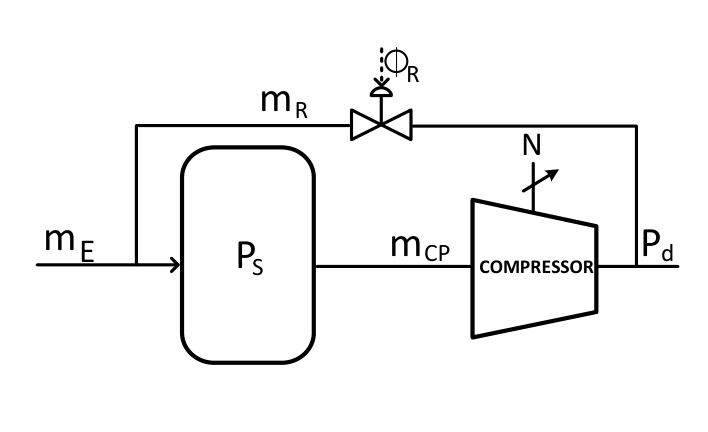

Usar **desvios normalizados** e tempo em **u.t.**; zero significa a condição inicial.
É um modelo linear local, não uma simulação completa da proteção antissurge.

In [1]:
%pip -q install control==0.10.2 ipywidgets scipy matplotlib
import numpy as np
import control as controle
import matplotlib.pyplot as plt
import ipywidgets as widgets
from scipy.optimize import least_squares
from IPython.display import display

plt.style.use('default')
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

## Os modelos
$u$: alteração da válvula; $d$: alteração da alimentação; $y$: desvio da vazão.

$$y=G_u u+G_d d,\quad
G_u=\frac{0{,}3211s+0{,}1927}{s^2+0{,}6s+0{,}16},\quad
G_d=\frac{0{,}3092s+0{,}08813}{s^2+0{,}672s+0{,}1764}.$$

In [2]:
s = controle.tf('s')
canal_acao = (0.3211*s + 0.1927) / (s**2 + 0.6*s + 0.16)
canal_perturbacao = (0.3092*s + 0.08813) / (s**2 + 0.672*s + 0.1764)

def responder(modelo, tempo, entrada):
    return np.asarray(controle.forced_response(modelo, tempo, entrada).outputs)

## Obter os dados do ensaio

Guardar **tempo, entrada e saída medida** depois de estimular a planta. Separar três ensaios com ruído: **ajuste**, **escolha** e **validação**. Os dados abaixo são simulados a partir dos modelos publicados.

Para usar dados próprios, enviar os CSVs a `dados_ensaio/` e mudar `usar_ensaio_externo` para `True`. Usar colunas `tempo,entrada,saida`, amostragem uniforme e desvios do ponto de operação, começando em equilíbrio. Manter a unidade de tempo e as escalas do canal.

In [3]:
from pathlib import Path
from scipy import signal
from scipy.optimize import least_squares

def guardar_ensaio(nome, tempo, entrada, saida):
    pasta = Path('dados_ensaio')
    pasta.mkdir(exist_ok=True)
    np.savetxt(pasta / f'{nome}.csv', np.column_stack([tempo, entrada, saida]),
               delimiter=',', header='tempo,entrada,saida', comments='')

In [4]:
usar_ensaio_externo = False
if not usar_ensaio_externo:
    tempo_ensaio = np.arange(0, 40.05, .05)
    entradas = {
        'ajuste': np.where(tempo_ensaio >= 2, .2, 0.),
        'escolha': np.select([tempo_ensaio < 3, tempo_ensaio < 18,
                             tempo_ensaio < 30], [0., .15, -.10], default=.05),
        'validacao': np.select([tempo_ensaio < 5, tempo_ensaio < 15,
                               tempo_ensaio < 28], [0., -.12, .18], default=0.)}
    numerador, denominador, _ = signal.cont2discrete(([.3211, .1927], [1., .6, .16]), .05)
    for numero, (nome, entrada) in enumerate(entradas.items()):
        saida = signal.lfilter(numerador.ravel(), denominador, entrada)
        medicao = saida + np.random.default_rng(12 + numero).normal(0, .004, len(saida))
        guardar_ensaio(f'{nome}_acao', tempo_ensaio, entrada, medicao)
print('Ler dados_ensaio/{ajuste,escolha,validacao}_acao.csv.')

Ler dados_ensaio/{ajuste,escolha,validacao}_acao.csv.


## Ler os dados

Separar a planta dos arquivos de identificação. O ajuste receberá somente os sinais lidos dos CSVs.

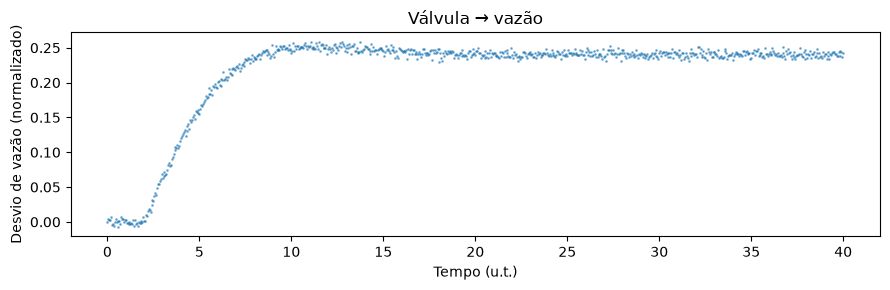

In [5]:
def ler_ensaio(nome):
    dados = np.genfromtxt(Path('dados_ensaio') / f'{nome}.csv', delimiter=',', names=True)
    tempo, entrada, saida = [np.asarray(dados[c], float) for c in ('tempo', 'entrada', 'saida')]
    if len(tempo) < 20 or not np.all(np.isfinite([tempo, entrada, saida])):
        raise ValueError('Fornecer pelo menos 20 amostras finitas de tempo, entrada e saída.')
    if not np.all(np.diff(tempo) > 0) or not np.allclose(np.diff(tempo), np.diff(tempo)[0]):
        raise ValueError('Usar amostragem uniforme, com tempo crescente.')
    if abs(entrada[0]) > 1e-10:
        raise ValueError('Remover o ponto de operação da entrada; iniciar em desvio zero.')
    return tempo - tempo[0], entrada, saida

canais = ['acao']
nomes_canais = {'acao': 'Válvula → vazão'}
unidades = {'tempo': 'Tempo (u.t.)', 'acao': 'Desvio de vazão (normalizado)'}
ensaios = {canal: {etapa: ler_ensaio(f'{etapa}_{canal}')
                    for etapa in ('ajuste', 'escolha', 'validacao')} for canal in canais}
figura, eixos = plt.subplots(1, len(canais), figsize=(9, 3), squeeze=False)
for canal, eixo in zip(canais, eixos.ravel()):
    tempo, entrada, saida = ensaios[canal]['ajuste']
    eixo.plot(tempo, saida, '.', ms=2, alpha=.5)
    eixo.set(title=nomes_canais[canal], xlabel=unidades['tempo'], ylabel=unidades[canal])
plt.tight_layout(); plt.show()

## Identificar P1D, P2D ou P3D

Comparar um, dois ou três **polos reais estáveis** e um **atraso estimado** (D): $\widehat G=K e^{-\theta s}/\prod_i(\tau_i s+1)$. São 3, 4 e 5 parâmetros, respectivamente. Ajustar somente no primeiro ensaio; não informar os parâmetros publicados ao identificador.

A planta publicada tem zero e polos complexos. Estes candidatos de polos reais são aproximações; a escolha não determina a ordem física do compressor.

In [6]:
def prever_modelo(modelo, ensaio):
    tempo, entrada, _ = ensaio
    denominador = np.array([1.0])
    for constante in modelo['constantes']:
        denominador = np.convolve(denominador, [constante, 1.0])
    entrada_atrasada = np.interp(tempo - modelo['atraso'], tempo, entrada, left=0)
    numerador, denominador, _ = signal.cont2discrete(
        ([modelo['ganho']], denominador), tempo[1] - tempo[0], method='zoh')
    return signal.lfilter(numerador.ravel(), denominador, entrada_atrasada)

def avaliar_modelo(modelo, ensaio):
    previsao = prever_modelo(modelo, ensaio)
    erro = ensaio[2] - previsao
    escala = np.linalg.norm(ensaio[2] - np.mean(ensaio[2]))
    ajuste = 100 * (1 - np.linalg.norm(erro) / escala) if escala > 0 else np.nan
    return ajuste, np.sqrt(np.mean(erro ** 2))

In [7]:
def identificar_modelo(ensaio, ordem):
    tempo, entrada, saida = ensaio
    duracao, passo = tempo[-1], tempo[1] - tempo[0]
    cauda = slice(-max(10, len(tempo) // 10), None)
    ganho_inicial = abs(np.median(saida[cauda]) / np.median(entrada[cauda]))
    if not np.isfinite(ganho_inicial) or ganho_inicial <= 0:
        raise ValueError('Usar um ensaio de ajuste com patamar final diferente de zero.')
    def montar(parametros):
        return {'ganho': parametros[0], 'constantes': np.sort(parametros[1:-1]),
                'atraso': parametros[-1], 'parametros': ordem + 2}
    limites = ([ganho_inicial / 20] + [passo / 10] * ordem + [0],
               [ganho_inicial * 20] + [duracao * 2] * ordem + [duracao / 4])
    ajustes = []
    for fracao in (0.06, 0.18):
        constantes = (np.geomspace(max(passo / 5, duracao * 0.002), duracao * fracao, ordem)
                      if ordem > 1 else [duracao * fracao])
        inicio = [ganho_inicial, *constantes, passo]
        ajuste = least_squares(lambda p: prever_modelo(montar(p), ensaio) - saida,
                               inicio, bounds=limites, x_scale='jac', max_nfev=250)
        ajustes.append(ajuste)
    melhor = min(ajustes, key=lambda resultado: resultado.cost)
    if not melhor.success:
        raise RuntimeError('O ajuste não convergiu; revisar o ensaio antes da sintonia.')
    return montar(melhor.x)

In [8]:
candidatos_modelo = {canal: {f'P{ordem}D': identificar_modelo(ensaios[canal]['ajuste'], ordem)
                             for ordem in (1, 2, 3)} for canal in canais}

## Escolher com parcimônia

Prever o segundo ensaio sem reajustar. Entre os modelos até **1 ponto percentual** do melhor FIT, escolher o de menos parâmetros. A tolerância é uma escolha didática, não um teste estatístico. FIT pode ser negativo.

In [9]:
def escolher_modelo(candidatos, ensaio_escolha, tolerancia=1.0):
    ajustes = {nome: avaliar_modelo(modelo, ensaio_escolha)[0]
               for nome, modelo in candidatos.items()}
    melhor = max(ajustes.values())
    elegiveis = [nome for nome in candidatos if ajustes[nome] >= melhor - tolerancia]
    return min(elegiveis, key=lambda nome: (candidatos[nome]['parametros'], -ajustes[nome]))

def reduzir_modelo(modelo):
    return np.array([modelo['ganho'], np.sum(modelo['constantes']), modelo['atraso']])

In [10]:
selecionados = {canal: escolher_modelo(candidatos_modelo[canal], ensaios[canal]['escolha'])
                for canal in canais}
print(f"{'Canal':<12}{'Modelo':<9}{'Parâmetros':>12}{'FIT escolha (%)':>18}  Seleção")
for canal in canais:
    for nome, modelo in candidatos_modelo[canal].items():
        ajuste = avaliar_modelo(modelo, ensaios[canal]['escolha'])[0]
        marca = '← parcimonioso' if nome == selecionados[canal] else ''
        print(f"{canal:<12}{nome:<9}{modelo['parametros']:>12}{ajuste:>18.2f}  {marca}")
modelos_reduzidos = {canal: reduzir_modelo(candidatos_modelo[canal][selecionados[canal]])
                    for canal in canais}

Canal       Modelo     Parâmetros   FIT escolha (%)  Seleção
acao        P1D                 3             90.93  
acao        P2D                 4             92.59  ← parcimonioso
acao        P3D                 5             92.56  


## Validar sem reajustar

Usar o terceiro ensaio somente depois da escolha. Conferir a previsão e o erro na unidade da saída. Não refazer o ajuste com esses dados.

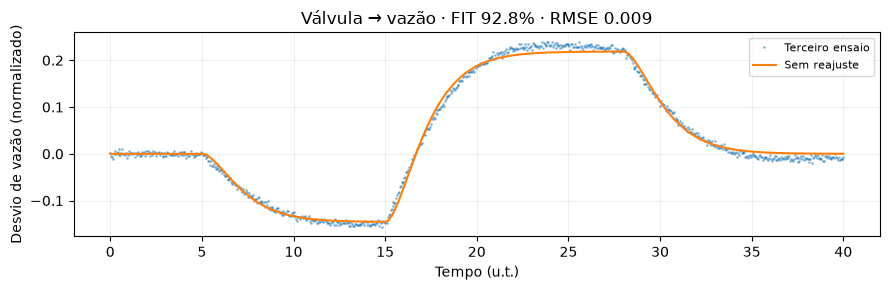

In [11]:
figura, eixos = plt.subplots(1, len(canais), figsize=(9, 3), squeeze=False)
erros_validacao = {}
for canal, eixo in zip(canais, eixos.ravel()):
    ensaio = ensaios[canal]['validacao']
    modelo = candidatos_modelo[canal][selecionados[canal]]
    ajuste, rmse = avaliar_modelo(modelo, ensaio)
    erros_validacao[canal] = rmse
    eixo.plot(ensaio[0], ensaio[2], '.', ms=2, alpha=.4, label='Terceiro ensaio')
    eixo.plot(ensaio[0], prever_modelo(modelo, ensaio), label='Sem reajuste')
    eixo.set(title=f'{nomes_canais[canal]} · FIT {ajuste:.1f}% · RMSE {rmse:.3f}',
             xlabel=unidades['tempo'], ylabel=unidades[canal])
    eixo.legend(fontsize=8); eixo.grid(alpha=.2)
plt.tight_layout(); plt.show()

## Sintonizar por IMC

Para P2D/P3D, usar $\tau_{eq}=\sum_i\tau_i$, preservando ganho e atraso. É uma aproximação para o projeto, não uma equivalência completa.

Aplicar $K_c=\tau_{eq}/[K(\lambda+\theta)]$ e $T_i=\tau_{eq}$. O modelo escolhido fornece os parâmetros do PI. O tempo IMC padrão é 4 u.t.; maior λ significa correção mais lenta.

In [12]:
def sintonizar_imc(ganho, constante_tempo, atraso, tempo_imc):
    ganho_pi = constante_tempo / (ganho * (tempo_imc + atraso))
    return ganho_pi * (1 + 1/(constante_tempo*s))

ganho_estimado, tempo_estimado, atraso_estimado = modelos_reduzidos['acao']
tempo_imc = 4.
controlador_pi = sintonizar_imc(ganho_estimado, tempo_estimado, atraso_estimado, tempo_imc)
print(f'PI de {selecionados["acao"]}: Kc = {tempo_estimado/(ganho_estimado*(tempo_imc+atraso_estimado)):.3f}; '
      f'Ti = {tempo_estimado:.3f} u.t.')

PI de P2D: Kc = 0.503; Ti = 2.443 u.t.


## Comparar as sintonias

Controlar a mesma planta com PIs derivados de estruturas diferentes, mantendo o mesmo λ. Se as curvas quase coincidirem, os polos adicionais não trouxeram diferença prática. O painel final conserva o modelo parcimonioso.

In [13]:
def comparar_sintonias(estrutura='P1D', tempo_imc=4.):
    tempo = np.linspace(0, 40, 501)
    plt.figure(figsize=(8, 3))
    for nome in dict.fromkeys([selecionados['acao'], estrutura]):
        ganho, constante, atraso = reduzir_modelo(candidatos_modelo['acao'][nome])
        controlador = sintonizar_imc(ganho, constante, atraso, tempo_imc)
        malha = controle.feedback(controlador * canal_acao)
        if np.any(controle.poles(malha).real >= 0):
            print(f'{nome}: malha instável; aumentar λ.'); continue
        resposta = controle.step_response(malha, tempo).outputs
        plt.plot(tempo, resposta, label=nome)
        print(f'{nome}: Kc = {constante/(ganho*(tempo_imc+atraso)):.3f}; Ti = {constante:.3f} u.t.')
    plt.axhline(1, color='gray', ls=':', label='Referência')
    plt.xlabel('Tempo (u.t.)'); plt.ylabel('Vazão (normalizada)'); plt.legend(); plt.grid(alpha=.2); plt.show()

widgets.interact(comparar_sintonias,
    estrutura=widgets.Dropdown(options=['P1D','P2D','P3D'], value='P1D', description='Comparar'),
    tempo_imc=widgets.FloatSlider(value=4, min=4, max=12, step=1,
        description='IMC λ', continuous_update=False));

interactive(children=(Dropdown(description='Comparar', options=('P1D', 'P2D', 'P3D'), value='P1D'), FloatSlide…

## A informação extra
A antecipação soma $u_{ff}=F d_{medido}$ à ação do PI.
Escolher $F=-G_d/G_u$: os efeitos se contrapõem.
Se a alimentação cair, o reciclo aumenta. A medida precisa chegar a tempo!

In [14]:
compensador = controle.minreal(-canal_perturbacao/canal_acao, verbose=False)
ganho_antecipacao = float(controle.dcgain(compensador))
print(f'Queda de alimentação de -0,20 → ação final de {ganho_antecipacao*(-0.2):+.3f}')

sensibilidade = controle.feedback(1, canal_acao*controlador_pi)
caminho_correcao = controle.minreal(sensibilidade*canal_perturbacao, verbose=False)
caminho_antecipacao = controle.minreal(sensibilidade*canal_acao*compensador, verbose=False)
caminho_acao_correcao = controle.minreal(-controlador_pi*caminho_correcao, verbose=False)
caminho_acao_antecipacao = controle.minreal(sensibilidade*compensador, verbose=False)

Queda de alimentação de -0,20 → ação final de +0.083


## Comparar as ações
A alimentação cai em 10 u.t. e retorna em 35 u.t. Compare o **desvio da vazão**
e o **comando da válvula**. O fator de ganho altera somente o efeito real da alimentação;
1 significa modelo correto. A medição da alimentação também tem um pequeno ruído.

In [15]:
tempo = np.arange(0, 60.05, 0.05)

def simular(queda=0.2, atraso_medida=0, fator_ganho=1, ruido_medida=0.003):
    perturbacao = -queda*((tempo >= 10) & (tempo < 35))
    medicao = np.interp(tempo-atraso_medida, tempo, perturbacao, left=0)
    ruido = np.random.default_rng(7).normal(0, ruido_medida, len(tempo))
    medicao = medicao + ruido
    saida_pi = fator_ganho*responder(caminho_correcao, tempo, perturbacao)
    saida_com_antecipacao = saida_pi + responder(caminho_antecipacao, tempo, medicao)
    acao_pi = fator_ganho*responder(caminho_acao_correcao, tempo, perturbacao)
    acao_com_antecipacao = acao_pi + responder(caminho_acao_antecipacao, tempo, medicao)
    return perturbacao, saida_pi, saida_com_antecipacao, acao_pi, acao_com_antecipacao

In [16]:
def comparar(queda, atraso_medida, fator_ganho):
    perturbacao, saida_pi, saida_ff, acao_pi, acao_ff = simular(
        queda, atraso_medida, fator_ganho)
    figura, eixos = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
    eixos[0].plot(tempo, saida_pi, color='#cc5b43', label='Só PI: reage ao erro')
    eixos[0].plot(tempo, saida_ff, color='#197c8b', label='PI + antecipação')
    eixos[0].axhline(0, color='0.5', lw=0.7)
    eixos[0].set_ylabel('Desvio da vazão [normalizado]')
    eixos[1].plot(tempo, acao_pi, color='#cc5b43', label='Só PI')
    eixos[1].plot(tempo, acao_ff, color='#197c8b', label='PI + antecipação')
    eixos[1].set(xlabel='Tempo [u.t.]', ylabel='Alteração da válvula [normalizada]')
    for eixo in eixos:
        eixo.axvline(10, color='0.6', ls=':', lw=1)
        eixo.axvline(10+atraso_medida, color='#197c8b', ls=':', lw=1)
        eixo.grid(alpha=0.2)
        eixo.legend(fontsize=9)
    plt.tight_layout()
    plt.show()
    pico_pi, pico_ff = np.max(np.abs(saida_pi)), np.max(np.abs(saida_ff))
    print(f'Maior desvio | só PI: {pico_pi:.3f} | PI + antecipação: {pico_ff:.3f}')
    print('Linha cinza: alimentação caiu. Linha verde: informação chegou.')

In [17]:
parametros = {
    'queda': widgets.FloatSlider(value=0.2, min=0.1, max=0.4, step=0.05,
                                description='Queda', continuous_update=False),
    'atraso_medida': widgets.FloatSlider(value=0, min=0, max=8, step=0.5,
                                       description='Atraso [u.t.]', continuous_update=False),
    'fator_ganho': widgets.FloatSlider(value=1, min=0.7, max=1.3, step=0.1,
                                      description='Efeito real', continuous_update=False),
}
painel = widgets.interactive_output(comparar, parametros)
display(widgets.VBox(list(parametros.values())), painel)

Output()

## Experimente
1. Deixe atraso = 0 e efeito real = 1. Quem abre a válvula primeiro?
2. Aumente o atraso. O controlador ainda consegue evitar o desvio inicial?
3. Volte o atraso para zero e mude o efeito real. Observe o PI corrigir o que sobrou.

**O diferencial:** agir pela perturbação medida, além de corrigir a saída.

## Referências
Modelo: Yang et al., *Controle regulatório PI+FeedForward antisurge aplicado a compressores
para plataformas de produção de petróleo e gás*, CBA 2018, eqs. 18–20; imagem: Fig. 2.
[Artigo](https://ojs.sba.org.br/index.php/cba/article/view/812).
Sintonia IMC: Rivera, Morari e Skogestad (1986), [DOI](https://doi.org/10.1021/i200032a041).
Referências completas, limites e materiais de apoio: [README](https://github.com/The-Celestino/toolbox-controle-classico/blob/main/estrategias/02_antecipacao/README.md).